In [1]:
from pathlib import Path
import h5py
import numpy as np
from scipy.io import loadmat
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# Use the full export path here if the MAT file is not beside this notebook.
data_path = Path("/home/philip_jacobson/Desktop/proj_coord_check_2.mat")
variable_names = ("y_full", "z_full", "I20", "I7", "I_ref")

if not data_path.is_file():
    raise FileNotFoundError(f"Set data_path to the exported MAT file; not found: {data_path.resolve()}")

if h5py.is_hdf5(data_path):
    # MATLAB v7.3 / Lumerical HDF5 arrays have reversed dimension order.
    with h5py.File(data_path, "r") as mat:
        data = {name: np.asarray(mat[name][()]).T for name in variable_names}
else:
    data = loadmat(data_path)

# Coordinates and monitor positions are in meters; maps are indexed by [y, z].
yp, zp = (np.asarray(data[name]).ravel() for name in ("y_full", "z_full"))
I20, I7, I_ref = (np.asarray(data[name]).squeeze() for name in ("I20", "I7", "I_ref"))

print(f"Loaded {data_path}: yp {yp.shape}, zp {zp.shape}")
print(f"Maps: I20 {I20.shape}, I7 {I7.shape}, I_ref {I_ref.shape}")


Loaded /home/philip_jacobson/Desktop/proj_coord_check_2.mat: yp (431,), zp (431,)
Maps: I20 (431, 431), I7 (431, 431), I_ref (431, 431)


In [2]:
# Change these values, then rerun this cell and the plotting cells below.
FONT_FAMILY = "Arial"  # Choose an installed font, e.g. "Arial" or "Times New Roman".
FONT_SIZE = 14  # points

plt.rcParams.update({
    "font.family": FONT_FAMILY,
    "savefig.dpi": 600,  # High resolution for exported images.
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE,
    "legend.title_fontsize": FONT_SIZE,
    "figure.titlesize": FONT_SIZE,
})

findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.


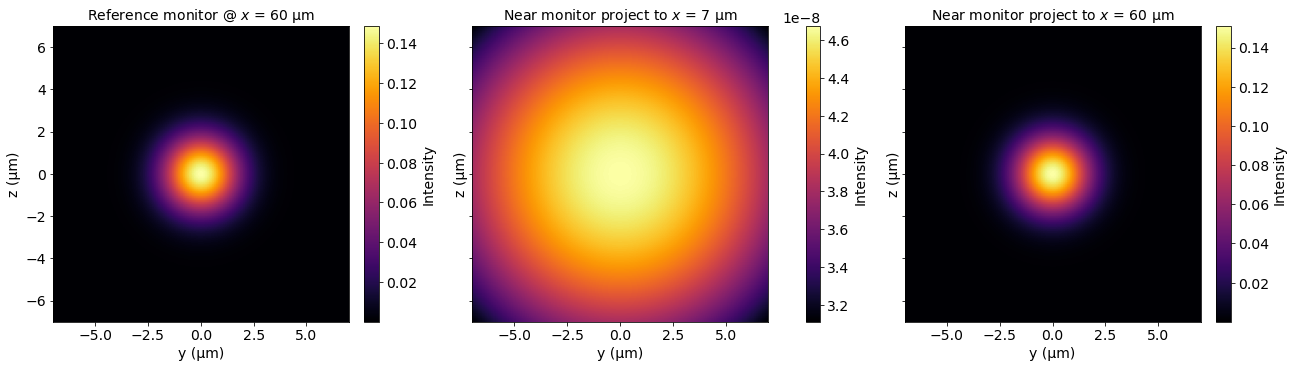

In [3]:
# Display each map with its own intensity scale and colorbar.
maps = [
    ("Reference monitor @ $x$ = 60 µm", I_ref),
    ("Near monitor project to $x$ = 7 µm", I7),
    ("Near monitor project to $x$ = 60 µm", I20),
]
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True,
                         constrained_layout=True)
for ax, (title, values) in zip(axes, maps):
    image = ax.pcolormesh(yp * 1e6, zp * 1e6, values.T,
                         shading="auto", cmap="inferno")
    ax.set(title=title, xlabel="y (µm)", ylabel="z (µm)")
    ax.set_aspect("auto")
    ax.set_box_aspect(1)
    fig.colorbar(image, ax=ax, label="Intensity")

plt.show()


findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.


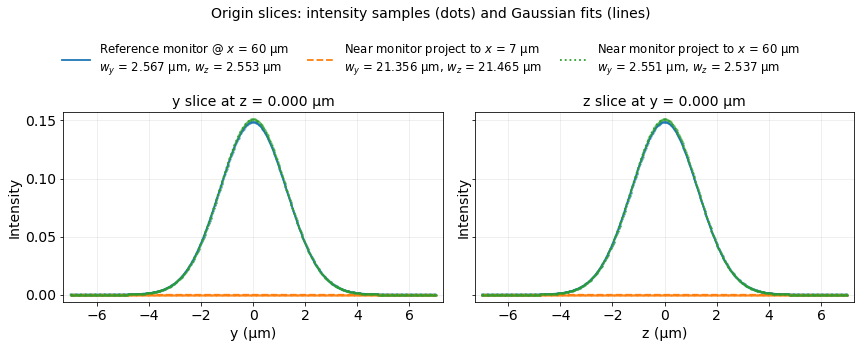

Fitted 1/e² intensity radii; fit includes a constant background.
Case                                           w_y (µm)   w_z (µm)      R²_y      R²_z
Reference monitor @ x = 60 µm                    2.5671     2.5534    1.0000    1.0000
Near monitor project to x = 7 µm                21.3565    21.4650    1.0000    1.0000
Near monitor project to x = 60 µm                2.5508     2.5369    1.0000    1.0000


In [4]:
from scipy.optimize import curve_fit

# Fit I(u) = background + amplitude * exp[-2 (u-center)^2 / w^2].
# The fitted w is the 1/e² intensity radius in µm (not the diameter).
def gaussian_intensity(u, amplitude, center, waist, background):
    return background + amplitude * np.exp(-2 * ((u - center) / waist)**2)


def fit_intensity_slice(position_um, intensity):
    scale = np.max(intensity)
    normalized = intensity / scale
    peak = int(np.argmax(normalized))
    background = float(np.min(normalized))
    half_height = background + (1 - background) / 2
    left = right = peak
    while left > 0 and normalized[left - 1] >= half_height:
        left -= 1
    while right < position_um.size - 1 and normalized[right + 1] >= half_height:
        right += 1
    spacing = np.min(np.abs(np.diff(position_um)))
    fwhm_guess = max(position_um[right] - position_um[left], spacing)
    waist_guess = fwhm_guess / np.sqrt(2 * np.log(2))
    parameters, _ = curve_fit(
        gaussian_intensity, position_um, normalized,
        p0=[1 - background, position_um[peak], waist_guess, background],
        bounds=([0, position_um.min(), spacing / 100, 0],
                [np.inf, position_um.max(), np.inf, np.inf]),
        maxfev=20000,
    )
    predicted = gaussian_intensity(position_um, *parameters)
    total = np.sum((normalized - normalized.mean())**2)
    r_squared = 1 - np.sum((normalized - predicted)**2) / total if total > 0 else np.nan
    parameters[[0, 3]] *= scale
    return {"parameters": parameters, "waist_um": parameters[2],
            "center_um": parameters[1], "r_squared": r_squared}


iy_zero = int(np.argmin(np.abs(yp)))
iz_zero = int(np.argmin(np.abs(zp)))
gaussian_results = {}
# Rectangular axes fill the figure; one shared legend sits above them.
fig_slices, slice_axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True,
                                     facecolor="white")
for (label, values), color, style in zip(maps, ["tab:blue", "tab:orange", "tab:green"],
                                        ["-", "--", ":"]):
    gaussian_results[label] = {}
    for ax, direction, position_um, intensity in [
        (slice_axes[0], "y", yp * 1e6, values[:, iz_zero]),
        (slice_axes[1], "z", zp * 1e6, values[iy_zero, :]),
    ]:
        fit = fit_intensity_slice(position_um, intensity)
        gaussian_results[label][direction] = fit
        dense_um = np.linspace(position_um.min(), position_um.max(), 2000)
        ax.plot(position_um, intensity, ".", color=color, markersize=3, alpha=0.5)
        ax.plot(dense_um, gaussian_intensity(dense_um, *fit["parameters"]),
                color=color, linestyle=style, linewidth=1.8,
                label=label + f"\n$w_{direction}$ = {fit['waist_um']:.3f} µm")

slice_axes[0].set(title=f"y slice at z = {zp[iz_zero] * 1e6:.3f} µm", xlabel="y (µm)")
slice_axes[1].set(title=f"z slice at y = {yp[iy_zero] * 1e6:.3f} µm", xlabel="z (µm)")
for ax in slice_axes:
    ax.set_ylabel("Intensity")
    ax.margins(x=0.02, y=0.04)
    ax.grid(alpha=0.25)
slice_title = fig_slices.suptitle("Origin slices: intensity samples (dots) and Gaussian fits (lines)", y=0.99)
slice_title.set_in_layout(False)
legend_handles, _ = slice_axes[0].get_legend_handles_labels()
legend_labels = [
    label + f"\n$w_y$ = {fits['y']['waist_um']:.3f} µm, $w_z$ = {fits['z']['waist_um']:.3f} µm"
    for label, fits in gaussian_results.items()
]
shared_legend = fig_slices.legend(
    legend_handles, legend_labels, loc="upper center", bbox_to_anchor=(0.5, 0.92),
    ncol=3, frameon=False, fontsize="small", columnspacing=1.5, handlelength=2.4,
)
# The header has its own reserved space; exclude it from tight_layout's margins.
shared_legend.set_in_layout(False)
# Reserve only the measured space needed by the legend.
fig_slices.canvas.draw()
legend_bottom = shared_legend.get_window_extent(fig_slices.canvas.get_renderer()).transformed(
    fig_slices.transFigure.inverted()).y0
fig_slices.tight_layout(rect=(0, 0, 1, legend_bottom - 0.015), pad=0.6, w_pad=1.0)
# Include the header in the notebook's tight crop after positioning the axes.
shared_legend.set_in_layout(True)
slice_title.set_in_layout(True)
plt.show()

print("Fitted 1/e² intensity radii; fit includes a constant background.")
print(f"{'Case':<44} {'w_y (µm)':>10} {'w_z (µm)':>10} {'R²_y':>9} {'R²_z':>9}")
for label, fits in gaussian_results.items():
    fy, fz = fits["y"], fits["z"]
    name = label.replace("$", "")
    print(f"{name:<44} {fy['waist_um']:10.4f} {fz['waist_um']:10.4f} "
          f"{fy['r_squared']:9.4f} {fz['r_squared']:9.4f}")
